# Step 3: Baselines before frontier models (can a cheap model fill in product categories?)

**Course:** Week 6 Day 3 of the LLM Engineering course: baselines and traditional ML.

## The problem we're solving

In [StyleSense](https://github.com/raghu619/stylesense-rag) the rule was: **budgets are a WHERE clause, vibes are a vector.** An LLM turns hard constraints (budget, gender, category) into a metadata filter, and only the taste part goes to vector search. That filter only works if every product carries a correct category. StyleSense got that for free from a synthetic catalogue.

Real catalogues don't. Categories are missing, inconsistent or wrong, and new products arrive every day. So the system needs a model that reads a product and fills in its category:

`new listing → category model → category → StyleSense filter (WHERE category = ...) → vector search for taste`

It's the same shape of problem as the course's Price is Right project: read a product description, predict one structured field. The course predicts a **price** (a number). This project predicts a **category** (one of 141 labels).

## Following the course arc on our own data

| Week 6 | Course (Amazon prices) | This project (Shopify categories) |
|---|---|---|
| Day 1 | Curate the data | Part 1: 25,022 products, 141 balanced categories |
| Day 2 | Rewrite products with an LLM | Part 2: gpt-4.1-nano rewrite for $0.77 |
| **Day 3** | **Baselines and classic ML** | **Part 3: this notebook** |
| Day 4 | Frontier LLMs | Next |
| Day 5 | Fine-tuning | Next |

## Why baselines before frontier models

- **A score means nothing on its own.** "The LLM gets 60%" could be great or terrible. With 141 categories, random guessing gets under 1%. The baseline tells you what 60% is worth.
- **Expensive models must earn their place.** A category model runs on every product in the catalogue, every time one is added or edited. A frontier model costs money and latency per product and sends the data out; a classic model costs almost nothing per prediction. A baseline shows exactly how much the LLM buys you.
- **Baselines catch bugs.** A simple model scoring suspiciously high usually means the answer is leaking into the input, like Part 1's candidate-category column, which contained the right answer for 100% of products. A fancy model that can't beat a simple one usually means a broken setup.
- **They show where the signal is.** In the course, switching from 3 hand-made features to word counts cut the error far more than switching models did.
- **They become the scoreboard** for the rest of Week 6: frontier LLMs (Day 4) and fine-tuning (Day 5) get compared against these numbers.

## This notebook's two questions

1. **What's the bar?** How well do cheap classic models, trained in seconds to minutes on a laptop, assign the category?
2. **Does the Part 2 rewrite help them?** Same models, same features, same settings. Only the input column changes: raw `text` vs rewritten `summary`.

## From prices to categories

Each Day 3 model has a classification twin:

| Day 3 (Amazon prices) | This project (141 categories) |
|---|---|
| `random_pricer` | Random category |
| `constant_pricer` (training average) | Most common category |
| `LinearRegression` | `LogisticRegression` |
| `RandomForestRegressor` | `RandomForestClassifier` |
| `XGBRegressor` | `XGBClassifier` |
| Average absolute error ($) | Accuracy and macro-F1 |

## Step 1: Load both text versions and read one product

**Why:** before measuring anything, confirm the data is the version we think it is (it must have Part 2's `summary` column), and read one product in both versions. Numbers come later. First, look.

**What the code does:**

1. Installs scikit-learn (bag of words, logistic regression, random forest) and XGBoost. Run once.
2. Loads train, validation and test from Hugging Face, the same dataset as Part 2.
3. Checks that the `summary` column exists.
4. Prints the split sizes, the number of categories and the median length of each text version.
5. Prints one product as raw text and as the LLM rewrite.

**What to check in the output:** 20,027 / 2,498 / 2,497 products, 141 categories, the rewrite about half the length of the raw text, and whether the rewrite kept the facts of the listing.

In [1]:
# Run once: scikit-learn (bag of words, logistic regression, random forest) and XGBoost.
# If an import fails right after this installs something new, restart the kernel.
%pip install --user -q scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 1: libraries, both text versions of our dataset, and one product side by side
import time                       # to time how long each model takes to train
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt   # charts for the README and the post (Step 7)
from pathlib import Path
from tqdm.auto import tqdm        # progress bars

REPO = "raghu619/shopify_category_lite"   # our dataset, including Part 2's summary column

# 1) Load the three splits from Hugging Face
splits = {}
for s in tqdm(["train", "validation", "test"], desc="Loading splits from Hugging Face", unit="split"):
    splits[s] = pd.read_parquet(f"hf://datasets/{REPO}/data/{s}.parquet")
train, val, test = splits["train"], splits["validation"], splits["test"]

# 2) Make sure this is the Part 2 version: raw text AND the LLM rewrite
assert {"text", "summary", "label"} <= set(train.columns), "No summary column: is this the Part 2 version of the dataset?"

# 3) Sizes and lengths
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} | {train['label'].nunique()} categories")
for col in ["text", "summary"]:
    print(f"{col:8s} median length: {train[col].str.len().median():.0f} characters")

# 4) Read one real product in both versions before modelling anything
row = train.iloc[5]
print(f"\nCategory: {row['label']}")
print("\nRAW TEXT:\n" + row["text"][:500])
print("\nLLM REWRITE:\n" + row["summary"])

Loading splits from Hugging Face:   0%|          | 0/3 [00:00<?, ?split/s]

train 20,027 | validation 2,498 | test 2,497 | 141 categories
text     median length: 578 characters
summary  median length: 260 characters

Category: Apparel & Accessories > Costumes & Accessories

RAW TEXT:
League of Legends Agony's Embrace Evelynn K/DA Skin Haut Cosplay Schuhe Lila
Material: Kunsteder Verarbeitungszeit: 5-7Tage

LLM REWRITE:
Title: League of Legends Agony's Embrace Evelynn K/DA Skin Cosplay Shoes Lilac
Brand: Unknown
Description: Cosplay shoes inspired by Evelynn's Agony's Embrace K/DA skin from League of Legends.
Details: Made of artificial leather, purple color, processing time 5-7 days.


### Step 1 findings

- The splits match Part 1: 20,027 / 2,498 / 2,497 products across 141 categories.
- The rewrite is 55% shorter: median 578 → 260 characters.
- The example is a German listing with a typo ("Kunsteder" for "Kunstleder"). The rewrite turned it into clean English and kept the facts: artificial leather, purple, 5 to 7 days. One small slip: "Lila" became "Lilac" in the title but "purple" in the details.
- Why this could matter: bag of words (Step 3) only knows the 2,000 most common training words, mostly English. The raw text gives it "schuhe", "lila", "kunsteder"; the rewrite gives it "cosplay", "shoes", "leather", "purple".

## Step 2: Know-nothing baselines

**Why:** before any real model, measure what zero intelligence gets you. These two set the floor. Every real model must clear them by a wide margin, or something is broken.

- **Random category:** pick one of the 141 at random. This is Day 3's `random_pricer`.
- **Most common category:** always guess the biggest training category. This is Day 3's `constant_pricer`. Part 1 capped every category, so the biggest one is small and this lands near 2%.

**How we score** (on the 2,497 test products, which are used only for final scores):

- **Accuracy:** the share of products that get the right category. Easy to read.
- **Macro-F1:** F1 for each category, then a plain average, so a 30-product category counts as much as a 400-product one. A model that ignores small categories can look fine on accuracy and bad here. F1 combines precision ("when I say Beverages, am I right?") and recall ("of all the Beverages, how many did I find?").

**What the code does:** defines `score()`, which prints one line per model and stores it in `results`, and `show_scoreboard()`, a bar chart of every result so far. The scoreboard grows after every model in Steps 4 to 6. Then it scores both baselines and draws the first scoreboard.

**What to check:** random lands near 1/141 ≈ 0.7%, and most common near 2%.

Random category       | none    | accuracy   0.8% | macro-F1 0.006
Most common category  | none    | accuracy   2.0% | macro-F1 0.000

Most common in training: Sporting Goods > Outdoor Recreation (400 products).
21 categories tie at that size because Part 1 capped every category, so this baseline lands near 2.0% whichever one is picked.


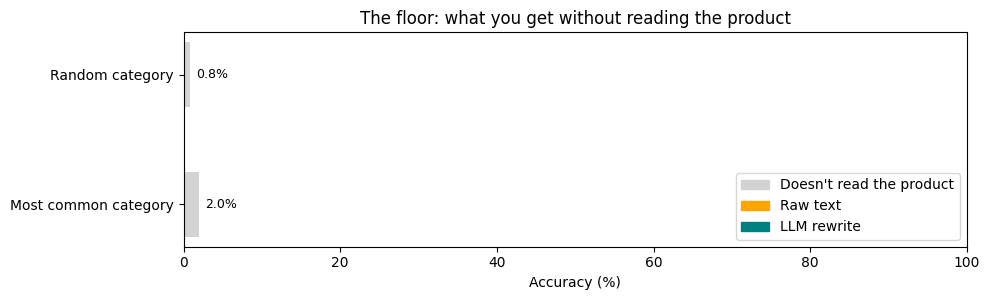

In [3]:
# Cell 2: how we score, a running scoreboard chart, and the two know-nothing baselines
from sklearn.metrics import accuracy_score, f1_score
from matplotlib.patches import Patch

results = []   # one row per (model, input); the scoreboard and Step 7 are built from this
COLORS = {"none": "lightgray", "text": "orange", "summary": "teal"}   # same colours as Part 2's length chart

def score(model_name, input_name, y_true, y_pred, seconds=None):
    """Score one model's test predictions, print one line, and keep the row for the results table."""
    row = {
        "model": model_name,
        "input": input_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "seconds": seconds,
    }
    results[:] = [r for r in results if (r["model"], r["input"]) != (model_name, input_name)]   # re-running a cell replaces its old result
    results.append(row)
    took = f" | trained in {seconds:.0f}s" if seconds is not None else ""
    print(f"{model_name:21s} | {input_name:7s} | accuracy {row['accuracy']:6.1%} | macro-F1 {row['macro_f1']:.3f}{took}")
    return row

def show_scoreboard(title="Scoreboard so far: accuracy on 2,497 test products"):
    """Draw every result scored so far: one gray bar per baseline, raw text vs LLM rewrite bars per model."""
    res = pd.DataFrame(results).drop_duplicates(["model", "input"], keep="last")
    models = list(dict.fromkeys(res["model"]))          # in the order they were scored
    fig, ax = plt.subplots(figsize=(10, 0.75 * len(models) + 1.6))
    for i, m in enumerate(models):
        rows = res[res["model"] == m]
        pair = len(rows) > 1
        for offset, (_, r) in zip([-0.19, 0.19] if pair else [0.0], rows.iterrows()):
            ax.barh(i + offset, r["accuracy"] * 100, height=0.36 if pair else 0.5, color=COLORS[r["input"]])
            ax.text(r["accuracy"] * 100 + 0.8, i + offset, f"{r['accuracy']:.1%}", va="center", fontsize=9)
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(models)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Accuracy (%)")
    ax.set_title(title)
    ax.legend(handles=[Patch(color=COLORS["none"], label="Doesn't read the product"),
                       Patch(color=COLORS["text"], label="Raw text"),
                       Patch(color=COLORS["summary"], label="LLM rewrite")], loc="lower right")
    plt.tight_layout()
    plt.show()

y_train, y_test = train["label"].values, test["label"].values
categories = np.array(sorted(train["label"].unique()))

# 1) A random category for every test product (fixed seed so the run is repeatable)
rng = np.random.default_rng(42)
score("Random category", "none", y_test, rng.choice(categories, size=len(test)))

# 2) The most common training category, for every test product
counts = train["label"].value_counts()
most_common = counts.index[0]
score("Most common category", "none", y_test, np.full(len(test), most_common))

ties = int((counts == counts.iloc[0]).sum())
print(f"\nMost common in training: {most_common} ({counts.iloc[0]} products).")
print(f"{ties} categories tie at that size because Part 1 capped every category, "
      f"so this baseline lands near {counts.iloc[0] / len(train):.1%} whichever one is picked.")

show_scoreboard("The floor: what you get without reading the product")

### Step 2 findings

- **Random category: 0.8%** accuracy (1 in 141 is 0.7%), macro-F1 0.006.
- **Most common category: 2.0%**, macro-F1 0.000. It's right for one category and wrong for the other 140, which is exactly what macro-F1 punishes.
- 21 categories tie at the 400-product cap, so "most common" is arbitrary (pandas picked Sporting Goods > Outdoor Recreation). Any of them scores 2.0%.
- **The floor is 2%.** Every real model below has to beat it by a wide margin.

## Step 3: Turn text into numbers (bag of words)

**Why:** classic models can't read. They need every product as a row of numbers. `CountVectorizer` does that exactly as in the course: it counts how many times each vocabulary word appears.

- `fit` learns the vocabulary: the 2,000 most frequent words across **training** products only, minus English stop words ("the", "with", "and").
- `transform` counts those same 2,000 words in validation and test products. Never refit on test: that would leak test words into the vocabulary, and a deployed model never gets to see future products in advance.

Each input gets its own vocabulary, because raw listings and rewrites use different words.

**What the code does:** builds the features for both inputs and prints, for each one, the matrix size, its 12 most frequent words, and how many test products contain **none** of the 2,000 words. Those products become a row of zeros: the model sees nothing at all. Then it shows the Step 1 cosplay shoes as each model will receive them, and draws a chart of how many vocabulary words each test product has. The rewrite's 5 format words (title, brand, description, details, unknown) appear in every rewrite and carry no product information, so the chart leaves them out.

**What to check:** which words dominate each vocabulary, how many test products end up all zeros, how much of the cosplay shoes survives in each version, and in the chart, which version leaves more products nearly invisible (0 to 3 words).

Building bag-of-words features:   0%|          | 0/2 [00:00<?, ?input/s]


text: 20,027 products x 2,000 words (on average 27 non-zero counts per product)
   12 most frequent words: ['material', 'use', 'easy', 'design', 'product', 'size', 'features', 'high', 'color', 'type', 'cm', 'en']
   test products with none of the 2,000 words: 58

summary: 20,027 products x 2,000 words (on average 19 non-zero counts per product)
   12 most frequent words: ['details', 'brand', 'title', 'description', 'unknown', 'designed', 'includes', 'suitable', 'set', 'steel', 'cm', 'color']
   test products with none of the 2,000 words: 0

Step 1 product (train row 5), word counts the model receives:
   text    : {'material': 1, 'da': 1, 'skin': 1}
   summary : {'title': 1, 'brand': 1, 'unknown': 1, 'description': 1, 'details': 1, 'color': 1, 'skin': 2, 'shoes': 2, 'inspired': 1, 'artificial': 1, 'leather': 1, 'purple': 1, 'processing': 1, 'time': 1, 'days': 1}

text    : median 23 vocabulary words per test product
summary : median 14 vocabulary words per test product


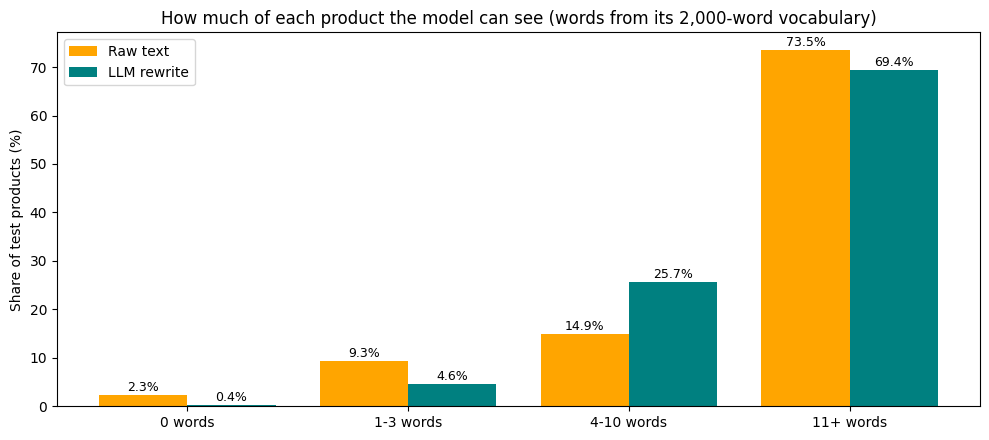

In [4]:
# Cell 3: bag of words for each input (fit on train only, then transform validation and test)
from sklearn.feature_extraction.text import CountVectorizer

INPUTS = ["text", "summary"]   # raw listing vs LLM rewrite
features = {}                  # input name -> (X_train, X_val, X_test, vectorizer)

for col in tqdm(INPUTS, desc="Building bag-of-words features", unit="input"):
    vectorizer = CountVectorizer(max_features=2000, stop_words="english")
    X_train = vectorizer.fit_transform(train[col])   # learn the 2,000-word vocabulary from training products only
    X_val = vectorizer.transform(val[col])           # count the SAME 2,000 words
    X_test = vectorizer.transform(test[col])
    features[col] = (X_train, X_val, X_test, vectorizer)

    vocab = vectorizer.get_feature_names_out()
    word_totals = np.asarray(X_train.sum(axis=0)).ravel()                  # how often each word appears in training
    top_words = vocab[np.argsort(word_totals)[::-1][:12]]
    empty_test = int((np.asarray(X_test.sum(axis=1)).ravel() == 0).sum())  # products with none of the 2,000 words
    print(f"\n{col}: {X_train.shape[0]:,} products x {X_train.shape[1]:,} words "
          f"(on average {X_train.nnz / X_train.shape[0]:.0f} non-zero counts per product)")
    print(f"   12 most frequent words: {list(top_words)}")
    print(f"   test products with none of the 2,000 words: {empty_test}")

# The Step 1 product, as each model will see it: only words that made it into the vocabulary survive
print("\nStep 1 product (train row 5), word counts the model receives:")
for col in INPUTS:
    X_train, _, _, vectorizer = features[col]
    product = X_train[5]
    kept = {w: int(c) for w, c in zip(vectorizer.get_feature_names_out()[product.indices], product.data)}
    print(f"   {col:8s}: {kept}")

# Chart: how much of each test product the model can actually see
FORMAT_WORDS = {"title", "brand", "description", "details", "unknown"}   # in every rewrite; carry no product information
bins, labels = [-1, 0, 3, 10, np.inf], ["0 words", "1-3 words", "4-10 words", "11+ words"]
shares = {}
print()
for col in INPUTS:
    _, _, X_test, vectorizer = features[col]
    content = np.array([w not in FORMAT_WORDS for w in vectorizer.get_feature_names_out()])
    distinct = np.asarray((X_test[:, content] > 0).sum(axis=1)).ravel()   # distinct vocabulary words per product
    shares[col] = pd.Series(pd.cut(distinct, bins=bins, labels=labels)).value_counts(normalize=True).reindex(labels) * 100
    print(f"{col:8s}: median {np.median(distinct):.0f} vocabulary words per test product")

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, col, name in [(-0.2, "text", "Raw text"), (0.2, "summary", "LLM rewrite")]:
    bars = ax.bar(x + offset, shares[col], width=0.4, color=COLORS[col], label=name)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Share of test products (%)")
ax.set_title("How much of each product the model can see (words from its 2,000-word vocabulary)")
ax.legend()
plt.tight_layout()
plt.show()

### Step 3 findings

- **The raw vocabulary is generic.** Its most frequent words are marketing filler ("material", "use", "easy", "design", "product"), plus "en", a Spanish and French word that slips past the English stop-word list.
- **The rewrite vocabulary starts with 5 format words** (details, brand, title, description, unknown). They appear in every rewrite and carry no product information. After them come descriptive words ("designed", "includes", "suitable").
- **58 test products (2.3%) are completely invisible as raw text:** none of their words are in the vocabulary, so the model gets a row of zeros. With the rewrite: 0.
- **The cosplay shoes:** from the raw German listing the model receives only `material`, `da` (from "K/DA") and `skin`. Nothing says shoes or costume. From the rewrite it receives `shoes` x2, `leather`, `purple`, `inspired`.
- **But the rewrite gives fewer words overall:** a median of 14 vocabulary words per product vs 23 for raw text. So the real question is now sharper: **more but noisier words, or fewer but cleaner ones?** The chart shows the trade: raw text leaves more products nearly invisible (0 to 3 words: 11.6% vs 5.0%), while the rewrite moves many products into the 4 to 10 word range.

## Step 4: Logistic regression

**Why:** this is the classification twin of Day 3's linear regression, and the simplest real model here.

- Linear regression gave every word **one price tag**. Logistic regression gives every word **one weight per category**: 2,000 words x 141 categories = 282,000 weights.
- For a product, each category's weights for its words are added up into a score. The 141 scores are turned into probabilities (softmax), and the highest one wins.
- Training adjusts the weights until the right category gets the highest probability on as many training products as possible.

It trains in seconds, so it's the first bar the slower models must beat.

**What the code does:** trains one logistic regression per input, scores it on the test set, prints its training accuracy too, updates the scoreboard, and prints the 8 highest-weight words for three categories, including the cosplay shoes' category.

**What to check:** how far above the 2% floor it lands, the gap between raw text and the rewrite, the gap between training and test accuracy, and whether the top words make sense.

Logistic regression:   0%|          | 0/2 [00:00<?, ?input/s]

Logistic regression   | text    | accuracy  39.5% | macro-F1 0.334 | trained in 5s
                        training accuracy 89.7% (the gap to test accuracy is memorisation)
Logistic regression   | summary | accuracy  49.8% | macro-F1 0.418 | trained in 5s
                        training accuracy 94.8% (the gap to test accuracy is memorisation)


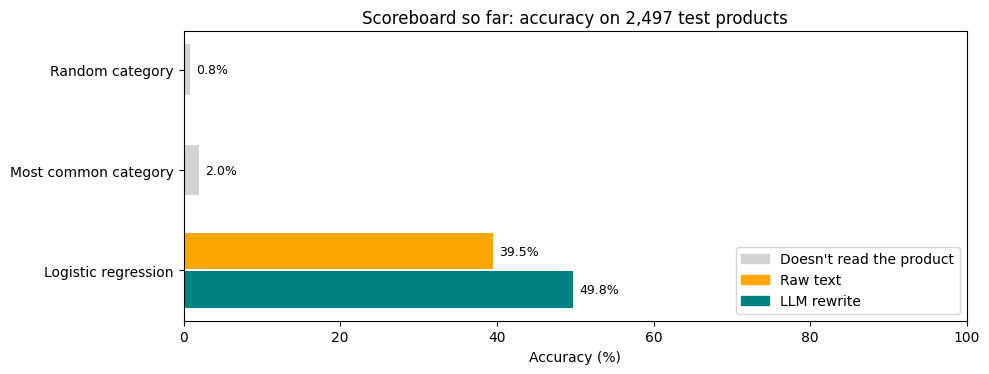

Highest-weight words (rewrite model):
   Food, Beverages & Tobacco > Beverages: ['cocktail', 'beverage', 'drink', 'coffee', 'flavored', '750ml', 'flavor', 'milk']
   Hardware > Tools: ['ladder', 'saw', 'tool', 'paint', 'knife', 'mixer', 'gun', 'welding']
   Apparel & Accessories > Costumes & Accessories: ['dress', 'inspired', 'shoes', 'mask', 'adults', 'themed', 'skirt', 'world']


In [5]:
# Cell 4: logistic regression on both inputs (the classification twin of Day 3's linear regression)
from sklearn.linear_model import LogisticRegression

lr_models, lr_preds = {}, {}   # kept for Step 8 (where did the rewrite help?)
for col in tqdm(INPUTS, desc="Logistic regression", unit="input"):
    X_train, X_val, X_test, _ = features[col]
    start = time.time()
    model = LogisticRegression(max_iter=2000)   # max_iter: enough optimisation steps to converge on 141 categories
    model.fit(X_train, y_train)
    lr_models[col], lr_preds[col] = model, model.predict(X_test)
    score("Logistic regression", col, y_test, lr_preds[col], time.time() - start)
    print(f"{'':21s}   training accuracy {accuracy_score(y_train, model.predict(X_train)):.1%} "
          f"(the gap to test accuracy is memorisation)")

show_scoreboard()

# What did the rewrite model learn? The 8 highest-weight words for three categories
model, vocab = lr_models["summary"], features["summary"][3].get_feature_names_out()
print("Highest-weight words (rewrite model):")
for category in ["Food, Beverages & Tobacco > Beverages", "Hardware > Tools", "Apparel & Accessories > Costumes & Accessories"]:
    weights = model.coef_[list(model.classes_).index(category)]
    print(f"   {category}: {list(vocab[np.argsort(weights)[::-1][:8]])}")

### Step 4 findings

- **Logistic regression: 39.5% on raw text, 49.8% on the rewrite.** Same model, same settings: the rewrite adds **10.3 points**. Macro-F1 rises too (0.334 → 0.418), so small categories gain as well, not just big ones.
- **Fewer but cleaner words won** (Step 3's question): the rewrite gives the model a median of 14 words instead of 23, and it scores higher.
- That's **20 to 25 times the 2% floor**, and it trained in **5 seconds** per input.
- **Memorisation:** training accuracy is 89.7% and 94.8%, test accuracy 39.5% and 49.8%. 282,000 weights for 20,027 products is a lot of freedom.
- **The weights make sense.** Beverages: cocktail, beverage, drink, coffee. Tools: ladder, saw, tool. Costumes: dress, inspired, **shoes**, mask. "Inspired" and "shoes" are exactly the words the rewrite gave the Step 1 cosplay shoes.

## Step 5: Random forest

**Why:** logistic regression adds up word weights independently, so it can't express "this word matters only together with that one". Trees can (Day 3's "tv" plus "remote" example). A random forest trains many deep trees, each on a random pick of training products, and lets them vote.

- **100 trees** (`n_estimators=100`), each grown until it fits its own random pick of products.
- One difference from the course: `RandomForestClassifier` also gives every split a random subset of words by default (`max_features="sqrt"`, about 45 of the 2,000). The course's `RandomForestRegressor` has that switched off.
- Each tree gives probabilities for the 141 categories; the forest averages them and picks the highest.

**What the code does:** trains one forest per input, scores both, prints training accuracy and how big the average tree is, and updates the scoreboard. About 20 to 40 seconds per input.

**What to check:** does the forest beat logistic regression? Does the rewrite help it by a similar amount? How big do the trees get?

Random forest:   0%|          | 0/2 [00:00<?, ?input/s]

Random forest         | text    | accuracy  35.8% | macro-F1 0.234 | trained in 3s
                        training accuracy 97.0% | average tree: 896 questions deep, 10,034 leaves
Random forest         | summary | accuracy  46.3% | macro-F1 0.364 | trained in 2s
                        training accuracy 99.2% | average tree: 590 questions deep, 10,216 leaves


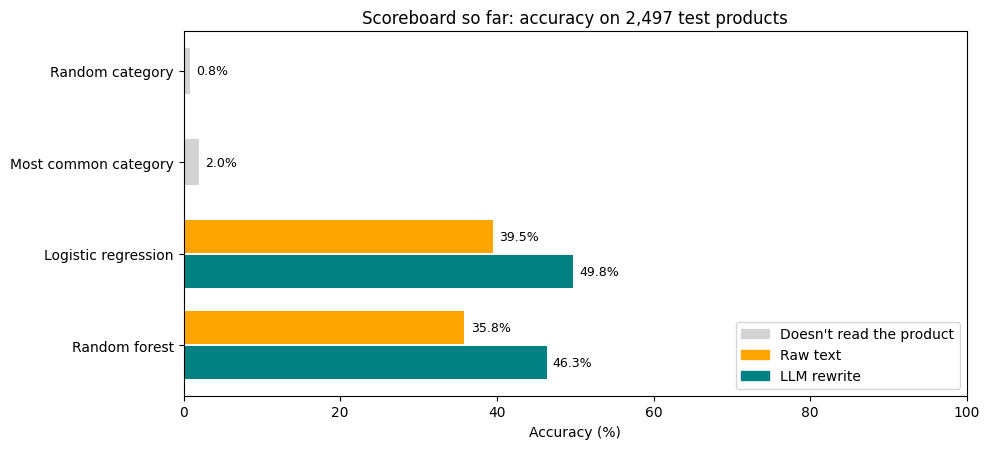

In [6]:
# Cell 5: random forest on both inputs (100 deep trees, each on a random pick of products, then they vote)
from sklearn.ensemble import RandomForestClassifier

for col in tqdm(INPUTS, desc="Random forest", unit="input"):
    X_train, X_val, X_test, _ = features[col]
    start = time.time()
    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)   # n_jobs=-1: use every CPU core
    model.fit(X_train, y_train)
    score("Random forest", col, y_test, model.predict(X_test), time.time() - start)
    depths = [tree.get_depth() for tree in model.estimators_]
    leaves = [tree.get_n_leaves() for tree in model.estimators_]
    print(f"{'':21s}   training accuracy {accuracy_score(y_train, model.predict(X_train)):.1%} | "
          f"average tree: {np.mean(depths):.0f} questions deep, {np.mean(leaves):,.0f} leaves")

show_scoreboard()

### Step 5 findings

- **Random forest: 35.8% on raw text, 46.3% on the rewrite.** The rewrite helps by **10.5 points**, almost exactly what it did for logistic regression.
- **The forest lost to logistic regression on both inputs** (35.8% vs 39.5%, 46.3% vs 49.8%). That's the opposite of the course, where the forest beat linear regression on prices. Macro-F1 is lower still (0.234 on raw text), so the forest neglects small categories more.
- **Why:** with text, evidence adds up word by word ("cocktail" + "flavor" + "750ml"). Logistic regression adds all the words at once. A tree asks about one word per split, so it needs very long paths to collect the same evidence. The average tree here is about 600 to 900 questions deep with around 10,000 leaves, close to one leaf per training product it saw. That's memorisation (97 to 99% training accuracy), and averaging 100 memorisers only partly fixes it.
- **The input moved accuracy more than the model did:** switching models changed accuracy by about 4 points; switching the text changed it by about 10, for both models.
- Fast: 2 to 3 seconds per input on all cores.

## Step 6: XGBoost

**Why:** the forest's trees are independent, and each one memorises its products. XGBoost does the opposite: small trees built one after another, each fixing the errors the earlier trees still make (Day 3's boosting), with `learning_rate=0.1` as in the course.

Two changes for 141 categories:

- **Each round builds 141 small trees**, one per category, each nudging that category's score. So 1,000 fixed rounds would mean 141,000 trees.
- **Early stopping instead of a fixed number of rounds:** after every round, XGBoost checks its loss on the **validation** set and stops once it hasn't improved for 20 rounds, keeping the best round. The test set stays untouched. The loss (multi-class log loss) measures how surprised the model is by the right answer: lower is better.

**What the code does:** trains one model per input with a progress bar, scores it, draws both learning curves (validation loss per round, best round marked), and updates the scoreboard. This is the slow one: about 1 to 5 minutes per input. The progress bar ends early when early stopping kicks in.

**What to check:** does boosting beat logistic regression? When did each run stop, and how do the two curves compare? How long did it take compared with logistic regression's 5 seconds?

XGBoost on text:   0%|          | 0/1000 [00:00<?, ?round/s]

XGBoost               | text    | accuracy  39.8% | macro-F1 0.313 | trained in 54s
                        stopped after round 227, best round 207 = 29,187 trees (141 per round)


XGBoost on summary:   0%|          | 0/1000 [00:00<?, ?round/s]

XGBoost               | summary | accuracy  48.4% | macro-F1 0.400 | trained in 58s
                        stopped after round 282, best round 262 = 36,942 trees (141 per round)


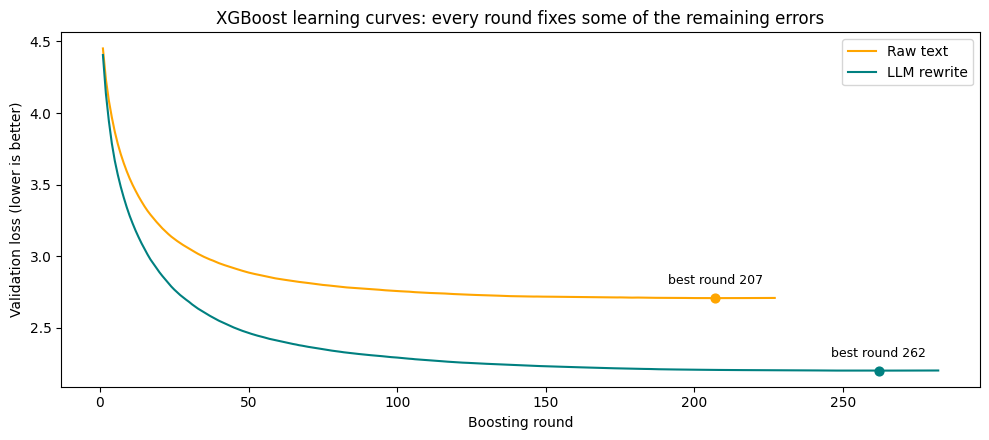

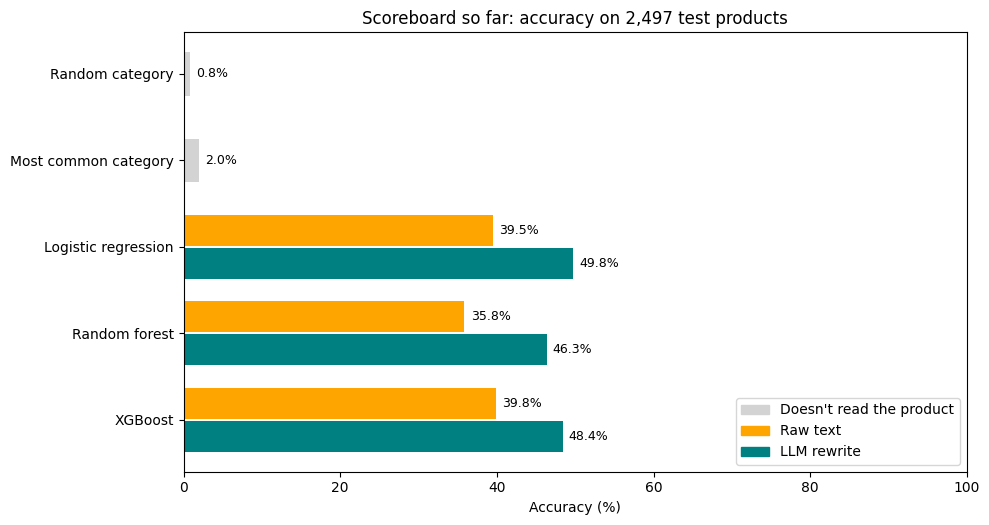

In [7]:
# Cell 6: XGBoost on both inputs, with early stopping on the validation set
try:
    import xgboost as xgb
except Exception as e:   # on a Mac this usually means the OpenMP library is missing
    raise ImportError("XGBoost failed to import. On a Mac run `brew install libomp` in Terminal, then restart the kernel.") from e
from sklearn.preprocessing import LabelEncoder

class TqdmCallback(xgb.callback.TrainingCallback):
    """One progress-bar tick per boosting round."""
    def __init__(self, total, desc):
        self.total, self.desc = total, desc
    def before_training(self, model):
        self.bar = tqdm(total=self.total, desc=self.desc, unit="round")
        return model
    def after_iteration(self, model, epoch, evals_log):
        self.bar.update(1)
        return False                 # False = keep going (early stopping can still end training)
    def after_training(self, model):
        self.bar.close()
        return model

encoder = LabelEncoder().fit(train["label"])     # XGBoost wants category numbers 0..140, not names
y_train_ids, y_val_ids = encoder.transform(train["label"]), encoder.transform(val["label"])

curves = {}   # validation loss per round, for each input
for col in INPUTS:
    X_train, X_val, X_test, _ = features[col]
    start = time.time()
    model = xgb.XGBClassifier(
        n_estimators=1000,          # upper limit; early stopping picks the real number of rounds
        learning_rate=0.1,          # same as the course
        early_stopping_rounds=20,   # stop once validation loss hasn't improved for 20 rounds
        eval_metric="mlogloss",     # multi-class log loss: how surprised the model is by the right answer
        tree_method="hist",         # fast histogram-based split finding
        n_jobs=-1,                  # use every CPU core
        random_state=42,
        callbacks=[TqdmCallback(1000, f"XGBoost on {col}")],
    )
    model.fit(X_train, y_train_ids, eval_set=[(X_val, y_val_ids)], verbose=False)
    preds = encoder.inverse_transform(model.predict(X_test))   # predict() uses the best round automatically
    score("XGBoost", col, y_test, preds, time.time() - start)
    best = model.best_iteration + 1
    curves[col] = (model.evals_result()["validation_0"]["mlogloss"], best)
    print(f"{'':21s}   stopped after round {len(curves[col][0])}, best round {best} "
          f"= {best * len(encoder.classes_):,} trees ({len(encoder.classes_)} per round)")

# Learning curves: validation loss after every round, best round marked
fig, ax = plt.subplots(figsize=(10, 4.5))
for col, name in [("text", "Raw text"), ("summary", "LLM rewrite")]:
    losses, best = curves[col]
    ax.plot(range(1, len(losses) + 1), losses, color=COLORS[col], label=name)
    ax.scatter([best], [losses[best - 1]], color=COLORS[col], s=40, zorder=3)
    ax.annotate(f"best round {best}", (best, losses[best - 1]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9)
ax.set_xlabel("Boosting round")
ax.set_ylabel("Validation loss (lower is better)")
ax.set_title("XGBoost learning curves: every round fixes some of the remaining errors")
ax.legend()
plt.tight_layout()
plt.show()

show_scoreboard()

### Step 6 findings

- **XGBoost: 39.8% on raw text, 48.4% on the rewrite** (+8.6 points).
- **It didn't beat logistic regression:** a 0.3-point edge on raw text, 1.4 points behind on the rewrite, and lower macro-F1 on both (0.313 vs 0.334, 0.400 vs 0.418).
- **It cost far more:** 54 to 58 seconds and 29,000 to 37,000 trees, against logistic regression's 5 seconds.
- **How to read the learning curves:** each point is the validation loss after that many rounds, on products the model never trained on (lower means it's less surprised by the right answer). Both curves drop steeply in the first ~50 rounds, where the early trees fix the big, easy mistakes, then flatten as later trees only fix details. Early stopping ended the runs at rounds 227 and 282 and kept the best rounds, 207 and 262. Running all 1,000 rounds would have spent about 75% of the time learning nothing.
- **The rewrite's curve is below the raw curve at every round:** on the rewritten text the model learns faster and ends better.

## Step 7: Results

**Why:** one table and one chart that answer this notebook's two questions. The chart is saved to `assets/` for the README and the LinkedIn post.

**What the code does:** builds the results table (accuracy, the rewrite's gain, macro-F1 and training time for each model) and draws the final chart. The chart's title is written from the numbers, so it says whatever the data says.

**What to check:** is the rewrite's gain consistent across models? Which model gives the best accuracy per second of training?

                    accuracy raw accuracy rewrite       gain macro-F1 raw macro-F1 rewrite training time (raw / rewrite)
model                                                                                                                   
Logistic regression        39.5%            49.8%  +10.3 pts        0.334            0.418                       5s / 5s
Random forest              35.8%            46.3%  +10.5 pts        0.234            0.364                       3s / 2s
XGBoost                    39.8%            48.4%   +8.5 pts        0.313            0.400                     54s / 58s

Floor: random category 0.8%, most common category 2.0%


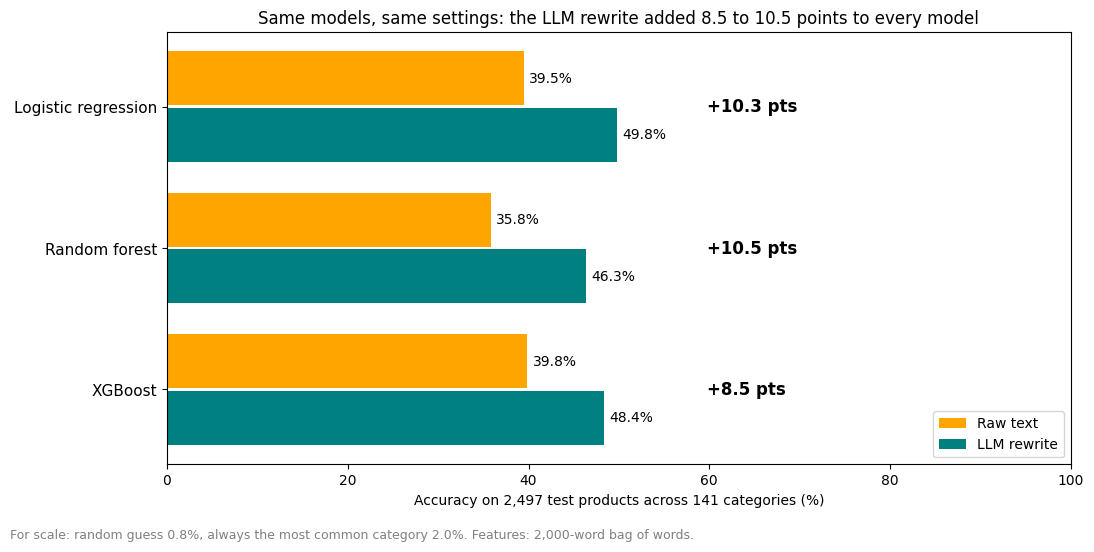

Saved assets/part3_raw_vs_rewrite.png


In [8]:
# Cell 7: final results table + the chart for the README and the post
res = pd.DataFrame(results).drop_duplicates(["model", "input"], keep="last")   # if a cell was re-run, keep its latest result
MODELS = ["Logistic regression", "Random forest", "XGBoost"]
models_only = res[res["model"].isin(MODELS)]
acc = models_only.pivot(index="model", columns="input", values="accuracy").loc[MODELS]
f1 = models_only.pivot(index="model", columns="input", values="macro_f1").loc[MODELS]
secs = models_only.pivot(index="model", columns="input", values="seconds").loc[MODELS]
gain = (acc["summary"] - acc["text"]) * 100          # accuracy points the rewrite added

table = pd.DataFrame({
    "accuracy raw": acc["text"].map("{:.1%}".format),
    "accuracy rewrite": acc["summary"].map("{:.1%}".format),
    "gain": gain.map("{:+.1f} pts".format),
    "macro-F1 raw": f1["text"].map("{:.3f}".format),
    "macro-F1 rewrite": f1["summary"].map("{:.3f}".format),
    "training time (raw / rewrite)": [f"{a:.0f}s / {b:.0f}s" for a, b in zip(secs["text"], secs["summary"])],
})
print(table.to_string())
floor = res[res["input"] == "none"].set_index("model")["accuracy"]
print(f"\nFloor: random category {floor['Random category']:.1%}, most common category {floor['Most common category']:.1%}")

# The chart: one row per model, raw vs rewrite, with the gain printed on the right
if (gain > 0).all():
    title = f"Same models, same settings: the LLM rewrite added {gain.min():.1f} to {gain.max():.1f} points to every model"
elif (gain < 0).all():
    title = f"Same models, same settings: the LLM rewrite cost every model {(-gain).max():.1f} to {(-gain).min():.1f} points"
else:
    title = "Same models, same settings: raw text vs LLM rewrite"

fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(MODELS))
for offset, col, name in [(-0.2, "text", "Raw text"), (0.2, "summary", "LLM rewrite")]:
    bars = ax.barh(y + offset, acc[col] * 100, height=0.38, color=COLORS[col], label=name)
    for b in bars:
        ax.text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%", va="center", fontsize=10)
gain_x = acc.values.max() * 100 + 10                   # one column for the gain labels, right of the longest bar
for i, g in enumerate(gain):
    ax.text(gain_x, i, f"{g:+.1f} pts", va="center", fontsize=12, fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels(MODELS, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel(f"Accuracy on {len(test):,} test products across 141 categories (%)")
ax.set_title(title, fontsize=12)
ax.legend(loc="lower right")
fig.text(0.01, 0.01, f"For scale: random guess {floor['Random category']:.1%}, always the most common category "
         f"{floor['Most common category']:.1%}. Features: 2,000-word bag of words.", fontsize=9, color="gray")
plt.tight_layout(rect=(0, 0.04, 1, 1))
Path("assets").mkdir(exist_ok=True)
plt.savefig("assets/part3_raw_vs_rewrite.png", dpi=150)
plt.show()
print("Saved assets/part3_raw_vs_rewrite.png")

### Step 7 findings

| Model | Raw text | LLM rewrite | Gain | Macro-F1 (raw → rewrite) | Training time |
|---|---|---|---|---|---|
| Logistic regression | 39.5% | **49.8%** | +10.3 pts | 0.334 → 0.418 | 5s |
| Random forest | 35.8% | 46.3% | +10.5 pts | 0.234 → 0.364 | 2 to 3s |
| XGBoost | 39.8% | 48.4% | +8.5 pts | 0.313 → 0.400 | 54 to 58s |

Floor: random category 0.8%, most common category 2.0%.

1. **The rewrite helped every model, by 8.5 to 10.5 points.** Three very different algorithms gained about the same, so it's the text, not a quirk of one model.
2. **The simplest model won.** Logistic regression on the rewrite: 49.8%, trained in 5 seconds. XGBoost took about 10 times longer for slightly less.
3. **The input moved accuracy more than the algorithm did.** Switching models changed accuracy by at most about 4 points; switching the text changed it by 8.5 to 10.5.
4. **The bar for any frontier model is now 49.8%** on this test set.

## Step 8: Where did the rewrite help?

**Why:** an average can hide where a gain comes from. If the rewrite mostly helps listings in other languages, that's a translation effect. If it helps everywhere, it's cleaner text in general. It also shows StyleSense where a cheap model is weakest.

The test products are split into three rough listing types, extending Day 1's common-word heuristic:

- **English sentences:** the listing reads like English.
- **Other language:** more common Spanish, French, German, Italian or Portuguese words than English ones, or a non-Latin script (Japanese, Cyrillic, ...).
- **No sentences:** bare titles, codes and spec lists with none of those common words.

It's a heuristic (it misses languages like Danish or Finnish), so read the split as rough.

**What the code does:** labels every test product, compares logistic regression on raw text vs the rewrite for each type, saves the chart for the README, counts the products the rewrite fixed and broke, and prints examples of both.

**What to check:** which listing type gains most, and what the rewrite broke.

Labelling listing types:   0%|          | 0/2497 [00:00<?, ?product/s]

                                   products share raw text rewrite       gain
listing                                                                      
English sentences                      1738   70%    48.4%   53.0%   +4.6 pts
No sentences (title or spec list)       399   16%    22.6%   36.8%  +14.3 pts
Other language                          360   14%    15.0%   48.3%  +33.3 pts


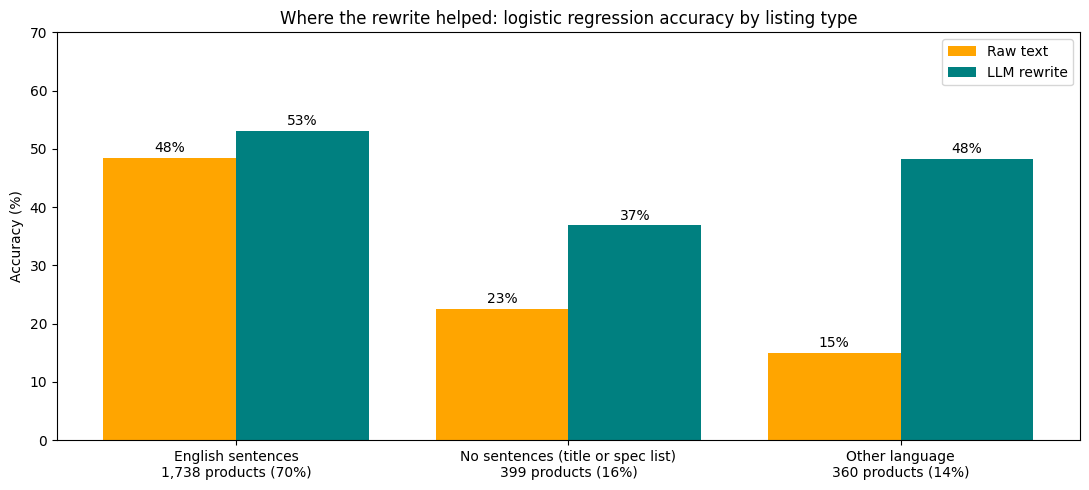

Saved assets/part3_by_listing_type.png

The rewrite fixed 483 products and broke 226 (net +257 of 2,497)

Fixed by the rewrite (other-language listings):

  RAW:      MAST - ARCHER S - Noir | IMPORTANT : Veuillez noter que les produits de la gamme MAST en précommande nécessitent
  REWRITE:  Title: MAST Archer S Wireless Rotary Tattoo Machine
  TRUE:          Business & Industrial > Piercing & Tattooing
  raw model:     Home & Garden > Household Appliances
  rewrite model: Business & Industrial > Piercing & Tattooing

  RAW:      Conjunto Elegante de 2 Peças com Picos Prateados - Castanho e Bege | Conjunto Elegante de 2 Peças com Picos Prat
  REWRITE:  Title: Elegant 2-Piece Set with Silver Pikes in Brown and Beige
  TRUE:          Apparel & Accessories > Clothing
  raw model:     Office Supplies > Office Instruments
  rewrite model: Apparel & Accessories > Clothing

  RAW:      Mangobuttermilch mit Passionsfrucht Łowicz 500g | Produktparameter Typ Buttermilch Typ Aromatisiert, trinkbar

In [9]:
# Cell 8: accuracy by listing type (logistic regression), plus products the rewrite fixed and broke
import re

EN_WORDS = r"\b(?:the|and|for|with|this|your|from|is|are|of|to|in|on)\b"
OTHER_WORDS = (r"\b(?:el|los|las|del|para|con|una|por|que|y|le|les|des|pour|avec|une|est|et|du|dans|"
               r"der|die|das|und|mit|für|ist|ein|eine|il|di|della|che|os|do|da|com|em)\b")
NON_LATIN = r"[Ͱ-ϿЀ-ӿ֐-׿؀-ۿ฀-๿぀-ヿ一-鿿가-힯]"

def listing_type(text):
    """Rough guess at what kind of listing a raw text is (extends Day 1's common-word heuristic)."""
    if len(re.findall(NON_LATIN, text)) >= 5:   # Greek, Cyrillic, Hebrew, Arabic, Thai, Japanese, Chinese, Korean
        return "Other language"
    lower = text.lower()
    en, other = len(re.findall(EN_WORDS, lower)), len(re.findall(OTHER_WORDS, lower))
    if en == 0 and other == 0:
        return "No sentences (title or spec list)"
    return "Other language" if other > en else "English sentences"

view = test[["text", "summary", "label"]].copy()
view["listing"] = [listing_type(t) for t in tqdm(view["text"], desc="Labelling listing types", unit="product")]
view["pred_raw"], view["pred_rewrite"] = lr_preds["text"], lr_preds["summary"]
view["raw_ok"] = view["pred_raw"] == view["label"]
view["rewrite_ok"] = view["pred_rewrite"] == view["label"]

ORDER = ["English sentences", "No sentences (title or spec list)", "Other language"]
by_type = view.groupby("listing").agg(products=("label", "size"), raw=("raw_ok", "mean"),
                                      rewrite=("rewrite_ok", "mean")).loc[ORDER]
print(pd.DataFrame({
    "products": by_type["products"],
    "share": (by_type["products"] / len(view)).map("{:.0%}".format),
    "raw text": by_type["raw"].map("{:.1%}".format),
    "rewrite": by_type["rewrite"].map("{:.1%}".format),
    "gain": ((by_type["rewrite"] - by_type["raw"]) * 100).map("{:+.1f} pts".format),
}).to_string())

# Chart for the README: raw vs rewrite accuracy for each listing type
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ORDER))
for offset, col, input_name, name in [(-0.2, "raw", "text", "Raw text"), (0.2, "rewrite", "summary", "LLM rewrite")]:
    bars = ax.bar(x + offset, by_type[col] * 100, width=0.4, color=COLORS[input_name], label=name)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([f"{t}\n{n:,} products ({n / len(view):.0%})" for t, n in zip(ORDER, by_type["products"])])
ax.set_ylim(0, 70)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Where the rewrite helped: logistic regression accuracy by listing type")
ax.legend()
plt.tight_layout()
plt.savefig("assets/part3_by_listing_type.png", dpi=150)
plt.show()
print("Saved assets/part3_by_listing_type.png")

# Which products changed? The rewrite fixes some predictions and breaks others
fixed = view[~view["raw_ok"] & view["rewrite_ok"]]
broke = view[view["raw_ok"] & ~view["rewrite_ok"]]
print(f"\nThe rewrite fixed {len(fixed):,} products and broke {len(broke):,} (net {len(fixed) - len(broke):+,} of {len(view):,})")

def show(rows, heading):
    print(f"\n{heading}")
    for _, r in rows.iterrows():
        print(f"\n  RAW:      {r['text'][:110].replace(chr(10), ' | ')}")
        print(f"  REWRITE:  {r['summary'].splitlines()[0]}")
        print(f"  TRUE:          {r['label']}")
        print(f"  raw model:     {r['pred_raw']}")
        print(f"  rewrite model: {r['pred_rewrite']}")

show(fixed[fixed["listing"] == "Other language"].head(3), "Fixed by the rewrite (other-language listings):")
show(broke.head(2), "Broken by the rewrite:")

### Step 8 findings

| Listing type | Products | Raw text | Rewrite | Gain |
|---|---|---|---|---|
| English sentences | 1,738 (70%) | 48.4% | 53.0% | +4.6 pts |
| No sentences (title or spec list) | 399 (16%) | 22.6% | 36.8% | +14.3 pts |
| Other language | 360 (14%) | 15.0% | 48.3% | +33.3 pts |

- **Translation gave the biggest gain.** For listings in other languages, accuracy more than tripled (15.0% → 48.3%), almost catching up with English listings. They're only 14% of the test products but account for almost half of the net gain (120 of the 257 extra correct answers). For English listings the rewrite added only 4.6 points.
- **Bare titles and spec lists gained 14 points.** The rewrite turns a terse listing into a sentence that names what the product is.
- **The raw-text model's mistakes are not subtle.** It filed a German listing for mango buttermilk under Hardware > Building Consumables, a French tattoo machine under Household Appliances, and a Portuguese two-piece outfit under Office Instruments. The rewrite model got all three right.
- **The rewrite has side effects too.** It fixed 483 products and broke 226 (net +257 of 2,497). Some breaks are real: a Spanish mechanic's creeper moved from Hardware to Retail. Some point at the labels themselves: "Finger Crayons" is labelled Office Supplies, and the rewrite model said Toys.

## Findings

**Q1: What's the bar?** Logistic regression on a 2,000-word bag of words reaches **49.8%** across 141 categories (random 0.8%, most common category 2.0%), trained in 5 seconds on a laptop. Any frontier model or fine-tune has to beat that to justify its cost per product.

**Q2: Does the Part 2 rewrite help?** Yes, for every model: **+8.5 to +10.5 points** with the same model and settings, even though the rewrite is 55% shorter. The gain is biggest for listings in other languages (15% → 48%, almost half of all the extra correct answers), then bare titles and spec lists (+14 points). English listings gained 4.6 points.

### What I learned

- **The input mattered more than the algorithm.** Switching the text moved accuracy about 10 points; switching models, at most about 4. It's the same lesson as the course's price project, on different data.
- **The course's winner didn't win here.** On prices, the forest and XGBoost beat linear regression. On text categories, plain logistic regression matched or beat both, in a fraction of the time. Text evidence adds up word by word, which suits a linear model.
- **Fewer, cleaner words beat more, noisier ones.** A median of 14 words per product beat 23.
- **Notebooks hide state.** Re-running a cell added a second copy of its result and broke the results table. `score()` now replaces old results, and the notebook was re-run top to bottom before publishing.

### What it means for StyleSense

A classic model filling in categories gets about half of them right. That's not good enough to trust as a WHERE clause on its own. The rewrite is the bigger lever, but it costs an LLM call for every product, now and at serving time (train/serve consistency). So the real question for Day 4 is: **rewrite + cheap classifier, or a frontier model classifying the product directly?**

**Next (Day 4):** frontier LLMs on the same 2,497 test products, against these numbers.